# MOSFET Characterization (Generic)

This notebook runs SPICE simulations on any N-channel MOSFET model using NgSpice via direct subprocess (batch mode) with proper convergence settings and realistic parasitic drain resistance (1 mOhm).

**Topology**: VDD+ -> R_drain -> Drain, VDD- (ground) -> Source, VGS+ -> Gate, VGS- -> Source (ground).

MOSFET source is node 0 (ground).

**Configuration**: Edit the MODEL_CONFIG section below to change MOSFET.


In [79]:
import sys
sys.path.insert(0, '.')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import subprocess
import os
import re
from pathlib import Path

matplotlib.rcParams['figure.figsize'] = (10, 6)
matplotlib.rcParams['font.size'] = 12

# ============================================================
# MODEL CONFIGURATION - Change these to switch MOSFETs
# ============================================================
MODEL_NAME = 'CSD19503KCS'           # Model name (subcircuit name in .lib)
LIB_FILENAME = 'ng_csd19503kcs.lib'  # Converted ngspice library file
R_DRAIN = 0.0                        # Series drain resistance (ohm) - SET TO 0 TO DISABLE
VGS_RANGE = (0, 10, 11)              # (start, stop, num_points) for output curves
VDS_RANGE = (0, 40, 0.1)             # (start, stop, step) for output curves
VGS_TRANSFER = (0, 10, 0.1)          # (start, stop, step) for transfer curve
VDD_TRANSFER = 10                    # Vdd for transfer curve (V)
# ============================================================

# Dynamic paths - find project root by looking for SpiceModels dir
def find_project_root():
    '''Find project root by searching for SpiceModels directory.'''
    cwd = Path.cwd()
    for path in [cwd] + list(cwd.parents):
        if (path / 'SpiceModels').exists():
            return path
    return cwd  # fallback

PROJECT_ROOT = find_project_root()
SPICE_MODELS_DIR = PROJECT_ROOT / 'SpiceModels'
LIB_PATH = SPICE_MODELS_DIR / LIB_FILENAME
WORK_DIR = PROJECT_ROOT
NGSPICE_CMD = r'C:\\Progra~1\\Spice64\\bin\\ngspice_con.exe'

# Auto-convert PSpice model if ngspice version doesn't exist
if not LIB_PATH.exists():
    pspice_lib = SPICE_MODELS_DIR / LIB_FILENAME.replace('ng_', '')
    if pspice_lib.exists():
        print(f"Converting {pspice_lib.name} -> {LIB_FILENAME}...")
        import subprocess
        result = subprocess.run([
            sys.executable, str(PROJECT_ROOT / 'convert_spice.py'), str(pspice_lib)
        ], capture_output=True, text=True, cwd=WORK_DIR)
        if result.returncode == 0:
            print("Conversion successful!")
        else:
            print(f"Conversion failed: {result.stderr}")
            raise FileNotFoundError(f"Could not create {LIB_FILENAME}")
    else:
        raise FileNotFoundError(f"Neither {LIB_FILENAME} nor {pspice_lib.name} found in {SPICE_MODELS_DIR}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Library: {LIB_PATH}")
print(f"Library exists: {LIB_PATH.exists()}")

# Extract model parameters from .lib file
def extract_model_params(lib_path):
    '''Extract key parameters from ngspice .lib file.'''
    content = lib_path.read_text(encoding='utf-8', errors='replace')
    
    params = {}
    
    # Extract .PARAM values (handles both 'name = value' and 'name value')
    param_pattern = re.compile(r'\.PARAM\s+(\w+)\s*=?\s*([^\n]+)')
    for match in param_pattern.finditer(content):
        name = match.group(1).lower()
        value_str = match.group(2).strip().rstrip(';')
        # Try to evaluate simple expressions
        try:
            # Clean up braces
            value_str = value_str.strip('{}')
            # Replace common parameter references with their values
            value_str = value_str.replace('pAA', str(params.get('paa', '10.856327')))
            value_str = value_str.replace('pWIDTH', str(params.get('pwidth', '1')))
            params[name] = float(eval(value_str))
        except:
            params[name] = value_str
    
    return params

model_params = extract_model_params(LIB_PATH)
print(f"Model: {MODEL_NAME}")
print(f"Working dir: {WORK_DIR}")
print(f"Series drain resistance: {R_DRAIN} ohm")
print(f"Extracted params: {list(model_params.keys())}")
for k, v in model_params.items():
    print(f"  {k} = {v}")

# Common capacitance parameters (with defaults)
CGSO = model_params.get('cgso', 17e-12)
CGDO = model_params.get('cgdo', 13.2e-12)
CJO = model_params.get('pcjo', 58e-12)
VJ = model_params.get('vj', 0.65)
M = model_params.get('m', 1.55)
FC = model_params.get('fc', 0.90)

# Geometry from model params - evaluate expressions if needed
paa = model_params.get('paa', 10.856327)
pwidth = model_params.get('pwidth', paa / 0.8 * 2)

# Handle case where pwidth is an expression string
if isinstance(pwidth, str):
    try:
        pwidth = float(eval(pwidth.strip('{}').replace('pAA', str(paa))))
    except:
        pwidth = paa / 0.8 * 2

W = pwidth
L = model_params.get('l', 0.70)
print(f"Geometry: W = {W:.2f} um, L = {L:.2f} um, W/L = {W/L:.1f}")

Project root: c:\Users\GNKRISHNAN\Documents\GitHub\PieceSpice
Library: c:\Users\GNKRISHNAN\Documents\GitHub\PieceSpice\SpiceModels\ng_csd19503kcs.lib
Library exists: True
Model: CSD19503KCS
Working dir: c:\Users\GNKRISHNAN\Documents\GitHub\PieceSpice
Series drain resistance: 0.0 ohm
Extracted params: ['ptrc1', 'ptrc2', 'pwidthp', 'pwidth', 'perimp', 'perim']
  ptrc1 = 0.0068
  ptrc2 = 2.1e-05
  pwidthp = 3.4994117647058824
  pwidth = pwidthP*1e6
  perimp = 2.1*pwidthP
  perim = perimP*1e6
Geometry: W = 27.14 um, L = 0.70 um, W/L = 38.8


In [80]:
def run_ngspice(netlist: str, timeout=120):
    '''Run ngspice batch mode and return stdout lines.'''
    import tempfile
    with tempfile.NamedTemporaryFile(mode='w', suffix='.cir', dir=WORK_DIR, delete=False) as f:
        f.write(netlist)
        netlist_path = f.name
    
    try:
        result = subprocess.run(
            [NGSPICE_CMD, '-b', netlist_path],
            capture_output=True,
            text=True,
            cwd=WORK_DIR,
            timeout=timeout
        )
        lines = result.stdout.split('\n')
        return lines, result.returncode, result.stderr
    finally:
        try:
            os.remove(netlist_path)
        except:
            pass

def parse_dc_output(lines):
    '''Parse DC sweep output from ngspice stdout.'''
    data_started = False
    x_vals = []
    y_vals = []
    for line in lines:
        if 'v-sweep' in line and ('vdd#branch' in line or 'vgs#branch' in line):
            data_started = True
            continue
        if data_started and line.strip():
            parts = line.split()
            if len(parts) >= 3:
                try:
                    idx = float(parts[0])
                    x = float(parts[1])
                    y = float(parts[2])
                    x_vals.append(x)
                    y_vals.append(y)
                except:
                    pass
    return np.array(x_vals), np.array(y_vals)

def run_dc_sweep_vds(vgs_val, vdd_start=VDS_RANGE[0], vdd_stop=VDS_RANGE[1], vdd_step=VDS_RANGE[2]):
    '''Run DC sweep of Vdd at fixed Vgs.'''
    # Build drain connection - direct if R_DRAIN=0, with resistor otherwise
    if R_DRAIN > 0:
        drain_connection = f'''Vdd vdd_node 0 {vdd_stop}
Vgs gate 0 {vgs_val}
Rdrain vdd_node drain {R_DRAIN}'''
    else:
        drain_connection = f'''Vdd drain 0 {vdd_stop}
Vgs gate 0 {vgs_val}'''
    
    netlist = f'''.title {MODEL_NAME}_Output_Vgs{vgs_val}
.OPTION PARHIER=LOCAL
.OPTION PSPICE
.OPTION GMIN=1e-12
.OPTION GMINDC=1e-12
.OPTION RELTOL=1e-3
.OPTION ABSTOL=1e-9
.OPTION VNTOL=1e-6
.OPTION ITL1=500
.OPTION ITL2=500
.OPTION PIVREL=1e-3
.OPTION CONVERGE=1
.OPTION METHOD=GEAR
.include {LIB_PATH}

XM1 drain gate 0 {MODEL_NAME}
{drain_connection}

.dc Vdd {vdd_start} {vdd_stop} {vdd_step}
.print dc I(Vdd)
.end
'''
    lines, rc, stderr = run_ngspice(netlist)
    if rc != 0:
        print(f"  [Vgs={vgs_val}V] ngspice failed (rc={rc}): {stderr[:200]}")
        return np.array([]), np.array([])
    return parse_dc_output(lines)

def run_dc_sweep_vgs(vdd_fixed=VDD_TRANSFER, vgs_start=VGS_TRANSFER[0], vgs_stop=VGS_TRANSFER[1], vgs_step=VGS_TRANSFER[2]):
    '''Run DC sweep of Vgs at fixed Vdd.'''
    # Build drain connection - direct if R_DRAIN=0, with resistor otherwise
    if R_DRAIN > 0:
        drain_connection = f'''Vdd vdd_node 0 {vdd_fixed}
Vgs gate 0 0
Rdrain vdd_node drain {R_DRAIN}'''
    else:
        drain_connection = f'''Vdd drain 0 {vdd_fixed}
Vgs gate 0 0'''
    
    netlist = f'''.title {MODEL_NAME}_Transfer_Vdd{vdd_fixed}
.OPTION PARHIER=LOCAL
.OPTION PSPICE
.OPTION GMIN=1e-12
.OPTION GMINDC=1e-12
.OPTION RELTOL=1e-3
.OPTION ABSTOL=1e-9
.OPTION VNTOL=1e-6
.OPTION ITL1=500
.OPTION ITL2=500
.OPTION PIVREL=1e-3
.OPTION CONVERGE=1
.OPTION METHOD=GEAR
.include {LIB_PATH}

XM1 drain gate 0 {MODEL_NAME}
{drain_connection}

.dc Vgs {vgs_start} {vgs_stop} {vgs_step}
.print dc I(Vdd)
.end
'''
    lines, rc, stderr = run_ngspice(netlist)
    if rc != 0:
        print(f"  [Vdd={vdd_fixed}V] ngspice failed (rc={rc}): {stderr[:200]}")
        return np.array([]), np.array([])
    return parse_dc_output(lines)

In [81]:
# Run DC sweep: Id vs Vds for multiple Vgs values
vgs_values = np.linspace(*VGS_RANGE)

id_vds_data = {}

for vgs in vgs_values:
    vds_swept, id_swept = run_dc_sweep_vds(vgs)
    id_vds_data[vgs] = (vds_swept, id_swept)
    
    if len(vds_swept) > 0:
        print(f"  Vgs={vgs:.1f}V: Id max={np.max(np.abs(id_swept))*1e3:.1f} mA, points={len(vds_swept)}")
    else:
        print(f"  Vgs={vgs:.1f}V: No data returned")

  Vgs=0.0V: Id max=0.0 mA, points=400
  Vgs=1.0V: Id max=0.0 mA, points=400
  Vgs=2.0V: Id max=0.0 mA, points=400
  Vgs=3.0V: Id max=143.1 mA, points=400
  Vgs=4.0V: Id max=68969.6 mA, points=400
  Vgs=5.0V: Id max=525079.0 mA, points=400
  Vgs=6.0V: Id max=1078610.0 mA, points=400
  Vgs=7.0V: Id max=1570780.0 mA, points=400
  Vgs=8.0V: Id max=1977080.0 mA, points=400
  Vgs=9.0V: Id max=2302730.0 mA, points=400
  Vgs=10.0V: Id max=2561880.0 mA, points=400


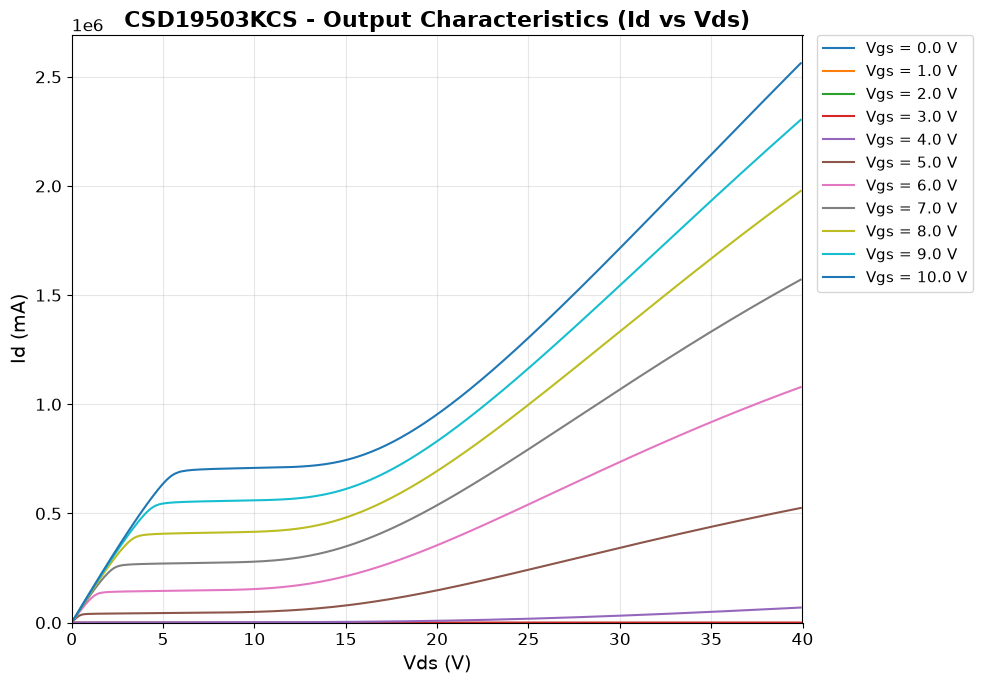

In [82]:
# Plot Id-Vds curves (Output Characteristics)
fig, ax = plt.subplots(figsize=(10, 7))

for vgs, (vds, id_vals) in id_vds_data.items():
    if len(vds) > 0:
        ax.plot(vds, np.abs(id_vals) * 1e3, label=f'Vgs = {vgs:.1f} V', linewidth=1.5)
    else:
        ax.axhline(y=0, color=f'C{int(vgs)}', linestyle='--', alpha=0.5, linewidth=1)

ax.set_xlabel('Vds (V)', fontsize=14)
ax.set_ylabel('Id (mA)', fontsize=14)
ax.set_title(f'{MODEL_NAME.upper()} - Output Characteristics (Id vs Vds)', fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=11)
ax.set_xlim(VDS_RANGE[0], VDS_RANGE[1])
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

Transfer curve at Vdd=10V: 101 points, Id max=708248.0 mA


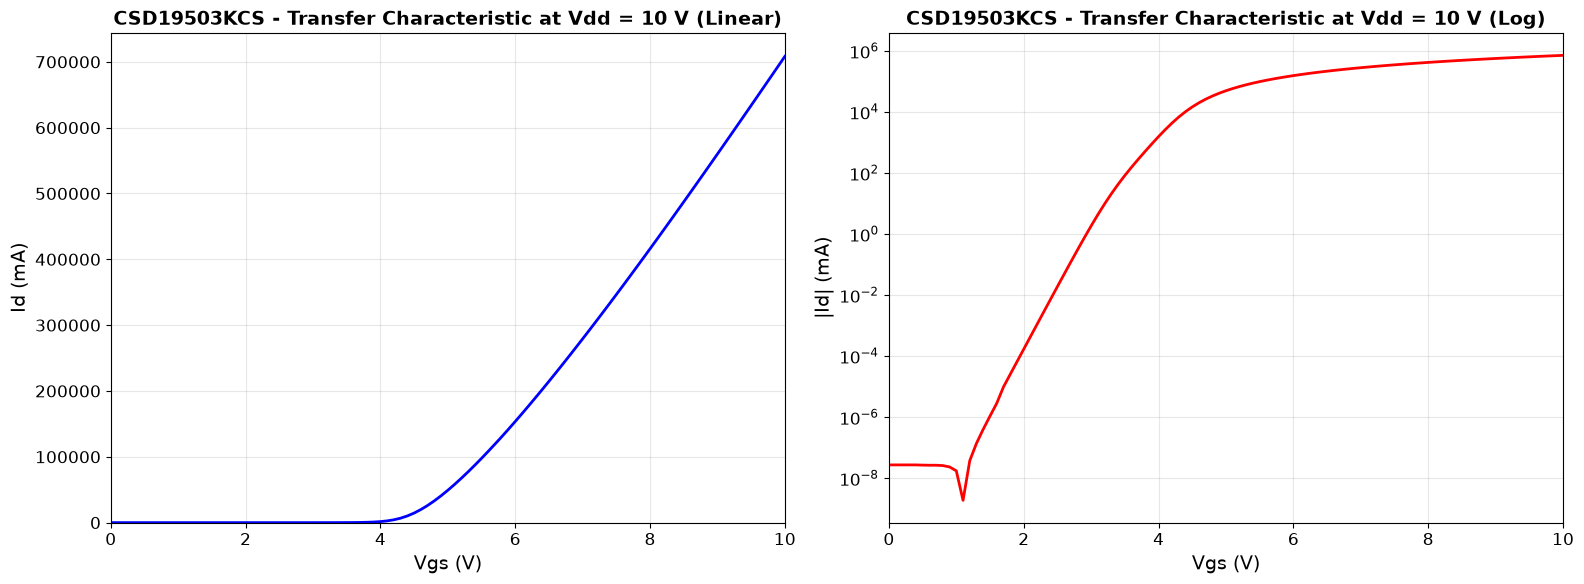

In [83]:
# Run transfer characteristic: Id vs Vgs at fixed Vdd
vdd_fixed = VDD_TRANSFER

vgs_swept, id_vgs = run_dc_sweep_vgs(vdd_fixed)

print(f"Transfer curve at Vdd={vdd_fixed}V: {len(vgs_swept)} points, Id max={np.max(np.abs(id_vgs))*1e3:.1f} mA")

# Plot Transfer Characteristics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Linear scale
ax1.plot(vgs_swept, np.abs(id_vgs) * 1e3, 'b-', linewidth=2)
ax1.set_xlabel('Vgs (V)', fontsize=14)
ax1.set_ylabel('Id (mA)', fontsize=14)
ax1.set_title(f'{MODEL_NAME.upper()} - Transfer Characteristic at Vdd = {vdd_fixed} V (Linear)', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.set_xlim(VGS_TRANSFER[0], VGS_TRANSFER[1])
ax1.set_ylim(bottom=0)

# Log scale
ax2.semilogy(vgs_swept, np.abs(id_vgs) * 1e3, 'r-', linewidth=2)
ax2.set_xlabel('Vgs (V)', fontsize=14)
ax2.set_ylabel('|Id| (mA)', fontsize=14)
ax2.set_title(f'{MODEL_NAME.upper()} - Transfer Characteristic at Vdd = {vdd_fixed} V (Log)', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3, which='both')
ax2.set_xlim(VGS_TRANSFER[0], VGS_TRANSFER[1])

plt.tight_layout()
plt.show()

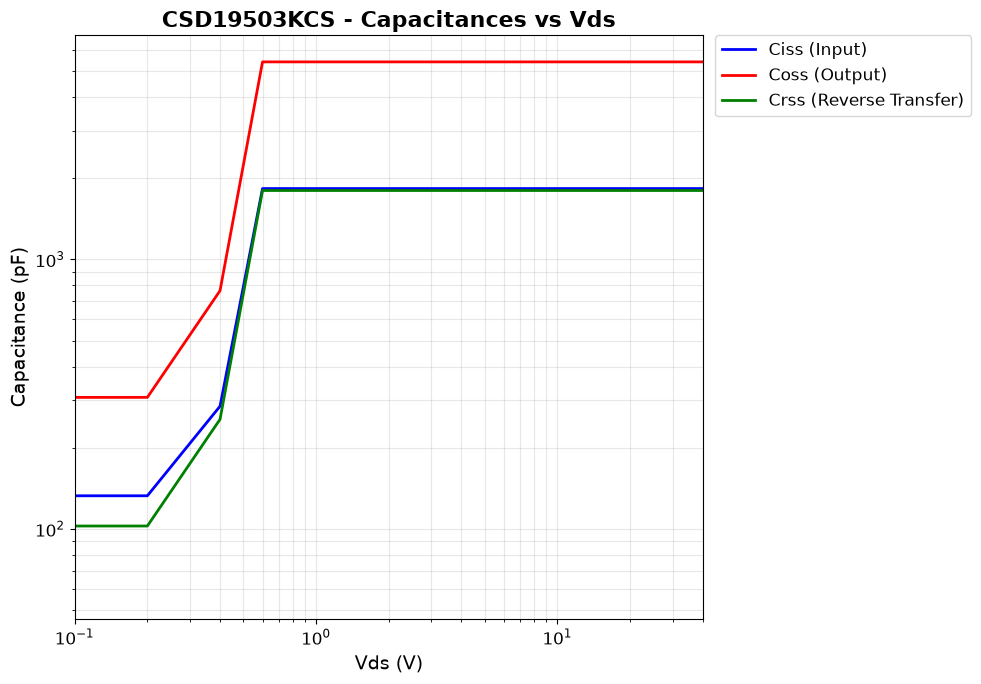

In [84]:
# Capacitance extraction: Ciss, Coss, Crss vs Vds (using model parameters)

vds_plot = np.linspace(0, 40, 201)

# Junction capacitance formula (clamped to avoid singularity at VJ*FC)
def c_junction(v, cjo, vj, m, fc):
    v_eff = min(v, vj * fc * 0.99)
    return cjo / (1 - v_eff/vj)**m

coss_plot = []
crss_plot = []
ciss_plot = []

for v in vds_plot:
    cds = c_junction(v, 2*CJO, VJ, M, FC)  # CDS0 uses 2*pCJO
    cdg = c_junction(v, CJO, VJ, M, FC)   # DD model
    
    coss_plot.append((cds + cdg) * 1e12)
    crss_plot.append(cdg * 1e12)
    ciss_plot.append((CGSO + CGDO + cdg) * 1e12)

# Plot Capacitances
fig, ax = plt.subplots(figsize=(10, 7))

ax.loglog(vds_plot, ciss_plot, 'b-', label='Ciss (Input)', linewidth=2)
ax.loglog(vds_plot, coss_plot, 'r-', label='Coss (Output)', linewidth=2)
ax.loglog(vds_plot, crss_plot, 'g-', label='Crss (Reverse Transfer)', linewidth=2)

ax.set_xlabel('Vds (V)', fontsize=14)
ax.set_ylabel('Capacitance (pF)', fontsize=14)
ax.set_title(f'{MODEL_NAME.upper()} - Capacitances vs Vds', fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3, which='both')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=12)
ax.set_xlim(0.1, 40)

plt.tight_layout()
plt.show()

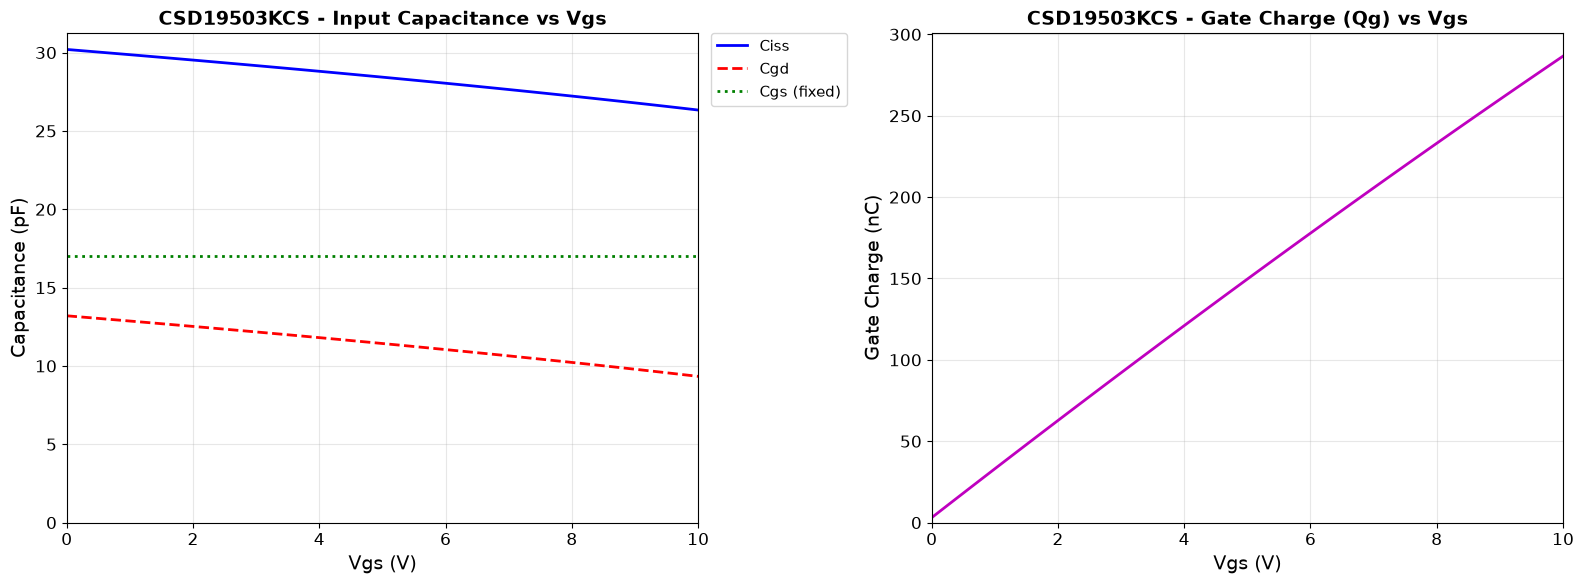

Total Qg at 10V: 286.6 nC


In [85]:
# Gate Charge (Qg) estimation from capacitances
# Qg = int Ciss dVgs from 0 to Vgs_max

vgs_q = np.linspace(0, 10, 101)
cgs_fixed = CGSO * 1e12  # pF
cgd_vgs = []

for vgs in vgs_q:
    # Cgd decreases with Vgs (Miller capacitance)
    cgd = CGDO * 1e12 * (1 - vgs/20)**0.5
    cgd_vgs.append(max(cgd, 0.1))

ciss_vgs = cgs_fixed + np.array(cgd_vgs)
qg = np.cumsum(ciss_vgs) * (vgs_q[1] - vgs_q[0])  # nC

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(vgs_q, ciss_vgs, 'b-', linewidth=2, label='Ciss')
ax1.plot(vgs_q, cgd_vgs, 'r--', linewidth=2, label='Cgd')
ax1.axhline(y=cgs_fixed, color='g', linestyle=':', linewidth=2, label='Cgs (fixed)')
ax1.set_xlabel('Vgs (V)', fontsize=14)
ax1.set_ylabel('Capacitance (pF)', fontsize=14)
ax1.set_title(f'{MODEL_NAME.upper()} - Input Capacitance vs Vgs', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=11)
ax1.set_xlim(0, 10)
ax1.set_ylim(bottom=0)

ax2.plot(vgs_q, qg, 'm-', linewidth=2)
ax2.set_xlabel('Vgs (V)', fontsize=14)
ax2.set_ylabel('Gate Charge (nC)', fontsize=14)
ax2.set_title(f'{MODEL_NAME.upper()} - Gate Charge (Qg) vs Vgs', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, 10)
ax2.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

print(f"Total Qg at 10V: {qg[-1]:.1f} nC")

In [86]:
# Threshold Voltage Extraction from Id-Vgs
# Use constant current method: Vth at Id = 1mA * (W/L)

print(f"W = {W:.2f} um, L = {L:.2f} um")
print(f"W/L = {W/L:.1f}")

from scipy.interpolate import interp1d

# Use the transfer curve data we already have
f_id = interp1d(vgs_swept, np.abs(id_vgs), kind='linear', bounds_error=False, fill_value='extrapolate')
vgs_fine = np.linspace(0, 10, 1001)
id_fine = f_id(vgs_fine)

# Vth at Id = 1mA * (W/L)
id_target = 1e-3 * (W/L)  # A
print(f"Target Id for Vth extraction: {id_target*1e3:.2f} mA")

# Find crossing
above = np.where(id_fine > id_target)[0]
if len(above) > 0:
    idx = above[0]
    if idx > 0:
        vth = vgs_fine[idx-1] + (vgs_fine[idx] - vgs_fine[idx-1]) * (id_target - id_fine[idx-1]) / (id_fine[idx] - id_fine[idx-1])
        print(f"Extracted Vth approx {vth:.3f} V")
    else:
        vth = None
        print("Vth below 0V")
else:
    vth = None
    print("Target current not reached")

W = 27.14 um, L = 0.70 um
W/L = 38.8
Target Id for Vth extraction: 38.77 mA
Extracted Vth approx 3.384 V


In [87]:
# On-resistance estimation at Vgs=10V (from output curve at highest Vgs)
# Rds(on) = Vds / Id at low Vds (linear region)
vgs_max = max(vgs_values)
vds_at_max, id_at_max = id_vds_data[vgs_max]

# Find point near Vds=0.1V for Rds(on) estimation
if len(vds_at_max) > 1:
    # Use first few points (low Vds) to estimate Rds_on
    mask = vds_at_max < 0.5
    if np.any(mask):
        vds_low = vds_at_max[mask]
        id_low = np.abs(id_at_max[mask])
        # Linear fit: Vds = Id * Rds_on
        if len(vds_low) >= 2:
            rds_on = np.polyfit(id_low, vds_low, 1)[0]  # slope = Rds_on
            print(f"Rds(on) at Vgs={vgs_max:.1f}V ≈ {rds_on*1e3:.2f} mΩ")
        else:
            rds_on = None
    else:
        rds_on = None
else:
    rds_on = None

# Summary of key parameters extracted
print("=" * 60)
print(f"{MODEL_NAME.upper()} MOSFET - Key Parameters Summary")
print("=" * 60)
print(f"Device: N-channel MOSFET")
print(f"Geometry: W = {W:.1f} um, L = {L:.2f} um, W/L = {W/L:.1f}")
print(f"Threshold Voltage (extracted): ~{vth:.2f} V" if vth else "Threshold Voltage: TBD")
print(f"Rds(on) at Vgs={vgs_max:.1f}V: {rds_on*1e3:.2f} mΩ" if rds_on else "Rds(on): TBD")
print(f"Ciss @ Vds=0V: {ciss_plot[0]:.0f} pF")
print(f"Coss @ Vds=0V: {coss_plot[0]:.0f} pF")
print(f"Crss @ Vds=0V: {crss_plot[0]:.0f} pF")
print(f"Ciss @ Vds=25V: {ciss_plot[125]:.0f} pF")
print(f"Coss @ Vds=25V: {coss_plot[125]:.0f} pF")
print(f"Crss @ Vds=25V: {crss_plot[125]:.0f} pF")
print(f"Total Gate Charge Qg(10V): {qg[-1]:.1f} nC")
print("=" * 60)

Rds(on) at Vgs=10.0V ≈ 7.14 mΩ
CSD19503KCS MOSFET - Key Parameters Summary
Device: N-channel MOSFET
Geometry: W = 27.1 um, L = 0.70 um, W/L = 38.8
Threshold Voltage (extracted): ~3.38 V
Rds(on) at Vgs=10.0V: 7.14 mΩ
Ciss @ Vds=0V: 88 pF
Coss @ Vds=0V: 174 pF
Crss @ Vds=0V: 58 pF
Ciss @ Vds=25V: 1831 pF
Coss @ Vds=25V: 5402 pF
Crss @ Vds=25V: 1801 pF
Total Gate Charge Qg(10V): 286.6 nC
